In [51]:
import numpy as np
import pandas as pd

In [67]:
# Data Loading
df = pd.read_csv('gold_churn_data.csv')
df.head()

,Unnamed: 0,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_years,spend_per_month
0,0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0.083333,29.850000
1,1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,...,No,No,One year,No,Mailed check,56.95,1889.50,No,2.833333,55.573529
2,2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0.166667,54.075000
3,3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,3.750000,40.905556
4,4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0.166667,75.825000


# Data Checking

In [68]:
# Removing Unnamed:0 column
df.drop(columns=['Unnamed: 0'],axis=1, inplace=True)

In [69]:
# Checking shape
df.shape

(7032, 23)

In [70]:
# Checking nulls
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
tenure_years        0
spend_per_month     0
dtype: int64

In [71]:
# Checking data types
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
tenure_years        float64
spend_per_month     float64
dtype: object

# Preparing data to training model

In [72]:
# Creating X and y
X = df.drop('Churn', axis=1)
y = df['Churn']

In [73]:
# Dropping Customer Id column
X = X.drop(columns=['customerID'])

In [74]:
# Converting TotalCharges column to numeric
X['TotalCharges'] = pd.to_numeric(X['TotalCharges'],errors='coerce')

In [75]:
# Converting Target columns to binary
y = y.map({'Yes':1, 'No':0})

In [76]:
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()

In [77]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [78]:
preprocessor = ColumnTransformer(transformers = [
    ('num',SimpleImputer(strategy='mean'),num_cols),
    ('cat',OneHotEncoder(handle_unknown='ignore'),cat_cols)
])

In [79]:
X_cleaned = preprocessor.fit_transform(X)

In [80]:
X_cleaned.shape

(7032, 47)

In [81]:
y_numpy = y.to_numpy()

In [82]:
y_numpy.shape

(7032,)

# Training the Model with XGB Classifier

In [83]:
from sklearn.model_selection import train_test_split

In [84]:
# Splitting the data 75/25 ratio for Train and Test
X_train, X_test, y_train, y_test = train_test_split(X_cleaned,y_numpy,test_size=0.25,random_state=42)

In [85]:
# Checking shapes
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5274, 47), (1758, 47), (5274,), (1758,))

In [86]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

In [87]:
# Creating XGBoost model
model= XGBClassifier()

In [88]:
# Training the model
model.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [89]:
# Predictions
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

# Checking Metrics

In [90]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

In [91]:
# Calculating Metrics
train_acc = accuracy_score(y_train,train_preds)
test_acc = accuracy_score(y_test,test_preds)

print("Train Accuracy:", round(train_acc,4))
print("Test Accuracy:", round(test_acc,4))

Train Accuracy: 0.9606
Test Accuracy: 0.7617


In [92]:
train_precision = precision_score(y_train,train_preds)
test_precision = precision_score(y_test,test_preds)

print("Train Precision:", round(train_precision,4))
print("Test Precision:", round(test_precision,4))

Train Precision: 0.9362
Test Precision: 0.5491


In [93]:
train_recall = recall_score(y_train,train_preds)
test_recall = recall_score(y_test,test_preds)

print("Train recall:", round(train_recall,4))
print("Test recall:", round(test_recall,4))

Train recall: 0.915
Test recall: 0.476


In [94]:
train_f1 = f1_score(y_train,train_preds)
test_f1 = f1_score(y_test,test_preds)

print("Train F1-score:", round(train_f1,4))
print("Test F1-score:", round(test_f1,4))

Train F1-score: 0.9254
Test F1-score: 0.5099


# Visualization

In [95]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

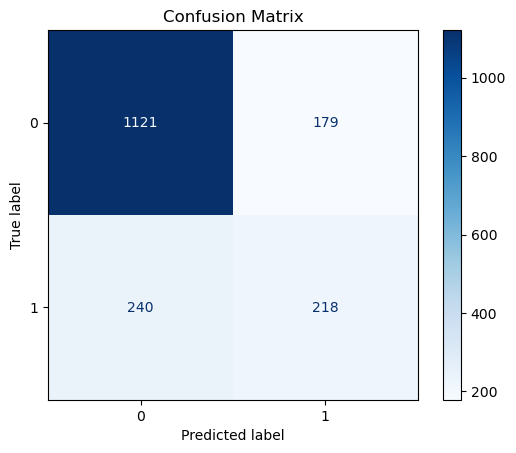

In [96]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

# Exporting the Trained Model

In [97]:
import joblib

joblib.dump(model, 'customer_churn.pkl')

['customer_churn.pkl']

In [98]:
X.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'tenure_years', 'spend_per_month'],
      dtype='object')

In [99]:
X.shape

(7032, 21)

# Converting Sample json to pkl

In [125]:
import json
with open('sample_input.json','r') as file:
    data = json.load(file)

sample_df = pd.DataFrame([data['customer']])
sample_df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_years,spend_per_month
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0.083333,29.85


In [135]:
sample_df.shape

(1, 21)

In [136]:
upd_df = X.copy()

In [137]:
upd_df = pd.concat([upd_df,sample_df], ignore_index=True)

In [138]:
upd_conv = preprocessor.fit_transform(upd_df)

In [161]:
sample_conv = upd_conv[-1,:].reshape(1,-1)
sample_conv

array([[ 0.        ,  1.        , 29.85      , 29.85      ,  0.08333333,
        29.85      ,  1.        ,  0.        ,  0.        ,  1.        ,
         1.        ,  0.        ,  1.        ,  0.        ,  0.        ,
         1.        ,  0.        ,  1.        ,  0.        ,  0.        ,
         1.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         1.        ,  1.        ,  0.        ,  0.        ,  1.        ,
         0.        ,  0.        ,  1.        ,  0.        ,  0.        ,
         1.        ,  0.        ,  0.        ,  1.        ,  0.        ,
         0.        ,  0.        ,  1.        ,  0.        ,  0.        ,
         1.        ,  0.        ]])

In [162]:
sample_conv.size

47

In [167]:
joblib.dump(sample_conv,'transformer.pkl')

['transformer.pkl']

In [195]:
joblib.dump(X,'input_dataset.pkl')

['input_dataset.pkl']

In [196]:
joblib.dump(preprocessor,'preprocessor.pkl')

['preprocessor.pkl']

# Testing Exported Pkl files

In [171]:
model_load = joblib.load('customer_churn.pkl')

In [172]:
sample_load = joblib.load('transformer.pkl')

In [179]:
# Prediction
pred = model_load.predict(sample_load)[0]
print("Yes" if pred == 1 else "No")

No


In [180]:
# Probability
probs = model_load.predict_proba(sample_load)
print(probs)

[[0.6274971  0.37250292]]


In [188]:
result = {
    "churn_probability": f"{probs[0][0]:.2f}",
    "churn_prediction": f"Yes" if pred == 1 else "No"
}
result

{'churn_probability': '0.63', 'churn_prediction': 'No'}

In [192]:
with open('result.json', 'w') as file:
    json.dump(result, file, indent=4, ensure_ascii=False)